In [ ]:
%pip install fitparse pandas numpy scikit-learn matplotlib seaborn

🚀 Scanning target directory for Garmin history files...
Found 9673 total items inside directory.
🎉 Success! 'master_df' compiled with 1284 consecutive calendar days.


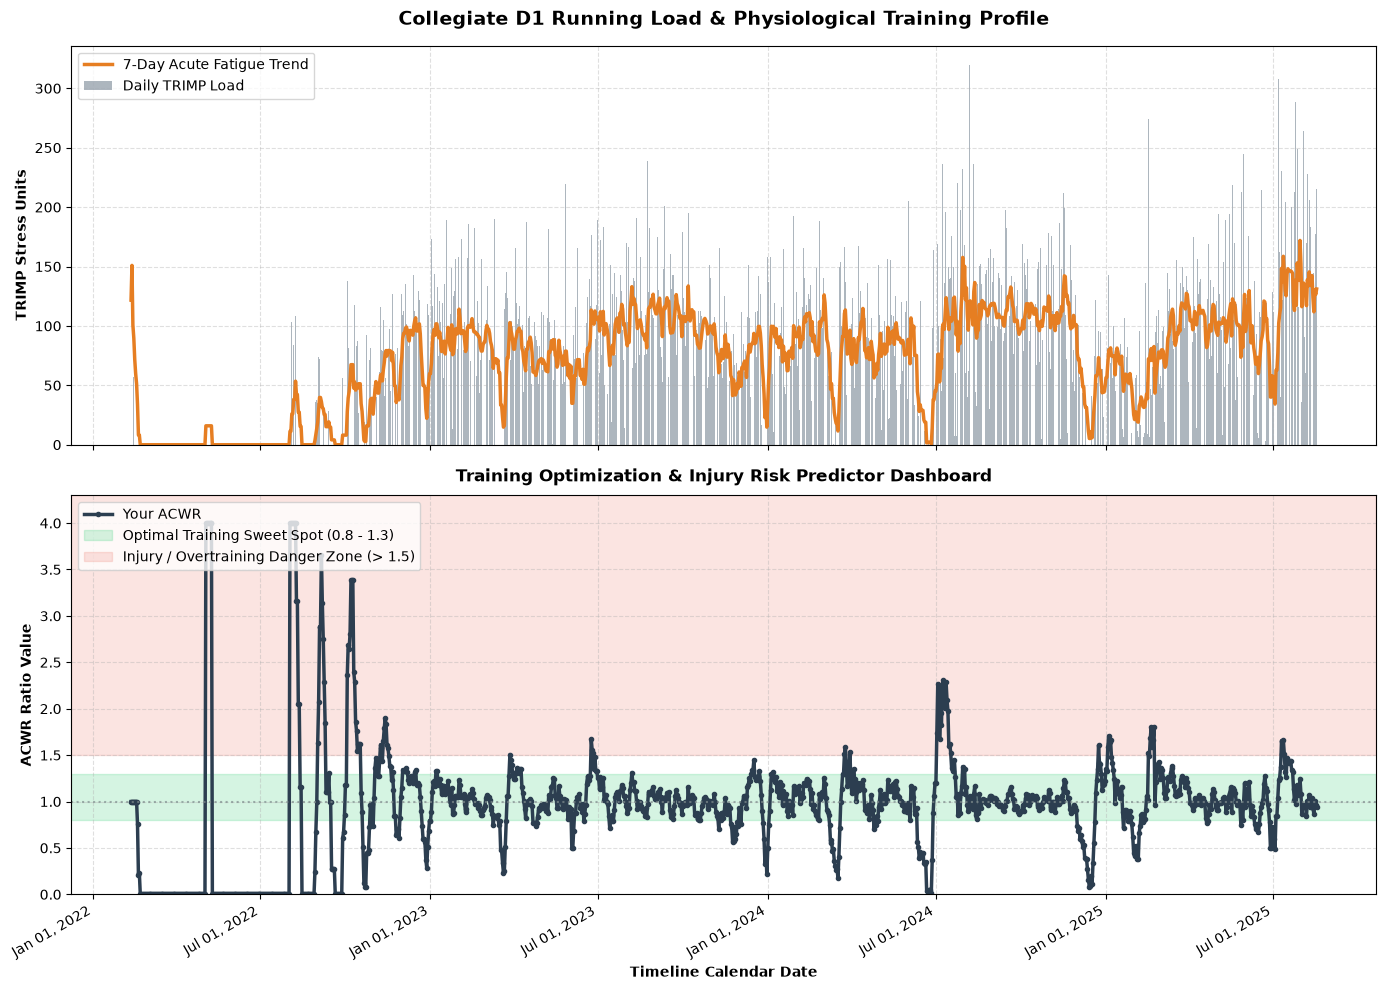

In [18]:
import os
import fitparse
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import zipfile
import io

# ====================================================
# 1. PARAMETERS & EXPLICIT ARCHIVE PATHWAY
# ====================================================
HR_MAX = 195         # Your tested D1 max heart rate
HR_REST = 45         # Your true morning resting heart rate
GENDER_FACTOR = 1.92 # Standard Banister constant for male profiles
FOLDER_PATH = '/Users/schumacher/Documents/Garmin Project/raw_fit_files/UploadedFiles_0-_Part1'

# ====================================================
# 2. MULTI-FORMAT EXTRACTION LOOP
# ====================================================
daily_records = []

print("🚀 Scanning target directory for Garmin history files...")
if not os.path.exists(FOLDER_PATH):
    print(f" Error: Folder does not physically exist at: {FOLDER_PATH}")
else:
    all_files = os.listdir(FOLDER_PATH)
    print(f"Found {len(all_files)} total items inside directory.")

    for index, file_name in enumerate(all_files):
        file_path = os.path.join(FOLDER_PATH, file_name)
        fitfile_object = None
        
        try:
            # Skip hidden background operating system files
            if file_name.startswith('.'):
                continue
                
            # Mode A: If file is a raw uncompressed .fit file
            elif file_name.lower().endswith('.fit'):
                fitfile_object = fitparse.FitFile(file_path)
                
            # Mode B: If file is a Garmin Connect zipped archive download
            elif file_name.lower().endswith('.zip'):
                with zipfile.ZipFile(file_path, 'r') as z:
                    for zipped_filename in z.namelist():
                        if zipped_filename.lower().endswith('.fit'):
                            file_bytes = z.read(zipped_filename)
                            fitfile_object = fitparse.FitFile(io.BytesIO(file_bytes))
                            break 
                            
            if fitfile_object is None:
                continue 
                
            # Core data telemetry log extraction
            records = []
            for record in fitfile_object.get_messages('record'):
                record_data = {}
                for data in record:
                    field_name = str(data.name).lower()
                    if field_name in ['timestamp', 'heart_rate', 'enhanced_speed', 'speed']:
                        record_data[field_name] = data.value
                if record_data:
                    records.append(record_data)
            
            if not records:
                continue
                
            df = pd.DataFrame(records)
            
            # Clean heart rate records
            if 'heart_rate' not in df.columns or df['heart_rate'].isna().all():
                continue
            df = df.dropna(subset=['heart_rate']).copy()
            
            # Time synchronization math
            df['timestamp'] = pd.to_datetime(df['timestamp'])
            df = df.sort_values('timestamp')
            workout_date = df['timestamp'].iloc[0].date()
            
            df['duration_min'] = df['timestamp'].diff().dt.total_seconds() / 60.0
            df['duration_min'] = df['duration_min'].fillna(0)
            
            # Physiological load weight calculations
            df['hr_reserve_fraction'] = (df['heart_rate'] - HR_REST) / (HR_MAX - HR_REST)
            df['hr_reserve_fraction'] = df['hr_reserve_fraction'].clip(0, 1) 
            
            df['trimp'] = (df['duration_min'] * df['hr_reserve_fraction'] * 
                           0.64 * np.exp(GENDER_FACTOR * df['hr_reserve_fraction']))
            
            # Distance mapping engine
            if 'enhanced_speed' in df.columns:
                df['raw_speed'] = df['enhanced_speed']
            elif 'speed' in df.columns:
                df['raw_speed'] = df['speed']
            else:
                df['raw_speed'] = 0
            total_miles = (df['raw_speed'] * (df['duration_min'] * 60)).sum() / 1609.34
            
            daily_records.append({
                'date': workout_date,
                'duration_minutes': df['duration_min'].sum(),
                'miles': total_miles,
                'trimp_score': df['trimp'].sum()
            })
                
        except Exception as e:
            pass

# ====================================================
# 3. TIME-SERIES CHRONOLOGICAL COMPILATION
# ====================================================
if len(daily_records) == 0:
    print("\n CRITICAL STOP: No data parsed from the location path.")
    print("Confirm files match '.fit' or '.zip' configurations inside that inner directory.")
else:
    master_df = pd.DataFrame(daily_records)
    master_df['date'] = pd.to_datetime(master_df['date'])
    master_df = master_df.groupby('date').sum().reset_index()
    master_df = master_df.sort_values('date').set_index('date')

    # Reindex to a complete continuous timeline so missing rest days are accounted for
    all_days = pd.date_range(start=master_df.index.min(), end=master_df.index.max(), freq='D')
    master_df = master_df.reindex(all_days, fill_value=0)
    master_df.index.name = 'date'

    # Rolling window tracking parameters
    master_df['acute_fatigue_7d'] = master_df['trimp_score'].rolling(window=7, min_periods=1).mean()
    master_df['chronic_fitness_28d'] = master_df['trimp_score'].rolling(window=28, min_periods=1).mean()
    master_df['acwr'] = master_df['acute_fatigue_7d'] / master_df['chronic_fitness_28d']
    master_df['acwr'] = master_df['acwr'].fillna(0).replace([np.inf, -np.inf], 0)

    print(f" Success! 'master_df' compiled with {len(master_df)} consecutive calendar days.")

    # ====================================================
    # 4. DATA SCIENCE DASHBOARD VISUALIZATION
    # ====================================================
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

    # Upper Visualization: Daily Stress Blocks vs 7-Day Running Trend
    ax1.bar(master_df.index, master_df['trimp_score'], color='#34495e', alpha=0.4, label='Daily TRIMP Load')
    ax1.plot(master_df.index, master_df['acute_fatigue_7d'], color='#e67e22', linewidth=2.5, label='7-Day Acute Fatigue Trend')
    ax1.set_title('Collegiate D1 Running Load & Physiological Training Profile', fontsize=14, fontweight='bold', pad=15)
    ax1.set_ylabel('TRIMP Stress Units', fontweight='bold')
    ax1.grid(True, linestyle='--', alpha=0.4)
    ax1.legend(loc='upper left')

    # Lower Visualization: Acute-to-Chronic Ratio Optimization Zones
    ax2.plot(master_df.index, master_df['acwr'], color='#2c3e50', linewidth=2.5, marker='o', markersize=3, label='Your ACWR')
    ax2.axhspan(0.8, 1.3, color='#2ecc71', alpha=0.2, label='Optimal Training Sweet Spot (0.8 - 1.3)')
    ax2.axhspan(1.5, max(2.2, master_df['acwr'].max() + 0.3), color='#e74c3c', alpha=0.15, label='Injury / Overtraining Danger Zone (> 1.5)')
    ax2.axhline(1.0, color='#7f8c8d', linestyle=':', alpha=0.7)

    ax2.set_title('Training Optimization & Injury Risk Predictor Dashboard', fontsize=12, fontweight='bold', pad=10)
    ax2.set_xlabel('Timeline Calendar Date', fontweight='bold')
    ax2.set_ylabel('ACWR Ratio Value', fontweight='bold')
    ax2.set_ylim(0, max(2.2, master_df['acwr'].max() + 0.3))
    ax2.grid(True, linestyle='--', alpha=0.4)
    ax2.legend(loc='upper left')

    # Date presentation styling
    ax2.xaxis.set_major_formatter(mdates.DateFormatter('%b %d, %Y'))
    fig.autofmt_xdate()
    plt.tight_layout()
    plt.show()
